# TED Talks Recommendation System — Problem-Driven Visual Analysis
### Module 2 | Decision-focused EDA

**Purpose:** Use the dataset to make evidence-based decisions about how the TED Talks recommendation system should work.

This notebook is not a collection of generic charts. Each visual answers a project question:
1. Is the catalogue suitable for content-based recommendations?
2. Which content fields are sufficiently available?
3. Which topics have enough coverage to support discovery?
4. How much transcript information is missing, and what fallback content can be used?
5. Are popularity signals available, and what limitations do they have?
6. What recommendation architecture is justified by the evidence?

**Important:** This notebook reads the raw CSV and creates analysis outputs only. It does not clean, overwrite, or train a model.

## 1. Objectives and skills

**Objectives**
- Assess dataset readiness for a TED Talks recommender.
- Identify usable content signals and data-quality risks.
- Translate observations into concrete system-design decisions.

**Skills**
- Pandas data profiling
- Missing-data analysis
- Topic and text analysis
- Data visualisation with Matplotlib/Seaborn
- Evidence-based recommender-system design

**Success criteria:** Every major chart should answer a project question and lead to an explicit design implication.

In [1]:
from pathlib import Path
import re, ast, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

print("Libraries loaded successfully.")

Libraries loaded successfully.


## 2. Locate and load the dataset

The notebook searches upward from the current working directory for the project dataset. If it cannot find it, set `PROJECT_ROOT` manually to your repository folder.

In [2]:
PROJECT_ROOT = None  # Example: Path(r"C:\Users\YourName\Desktop\Infosys-SpringBoard-Internship")

if PROJECT_ROOT is not None:
    PROJECT_ROOT = Path(PROJECT_ROOT)
else:
    here = Path.cwd()
    for candidate in [here, *here.parents]:
        if (candidate / "Scraped" / "Data" / "Raw" / "ted_talks.csv").exists():
            PROJECT_ROOT = candidate
            break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate Scraped/Data/Raw/ted_talks.csv. "
        "Set PROJECT_ROOT to your repository root in this cell."
    )

DATA_PATH = PROJECT_ROOT / "Scraped" / "Data" / "Raw" / "ted_talks.csv"
OUTPUT_DIR = PROJECT_ROOT / "Module_2_Data_Exploration_Preprocessing" / "outputs"
VIZ_DIR = OUTPUT_DIR / "visualizations" / "problem_driven"
REPORT_DIR = OUTPUT_DIR / "reports"
STATS_DIR = OUTPUT_DIR / "statistics"

for folder in [VIZ_DIR, REPORT_DIR, STATS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Dataset: {DATA_PATH}")
print(f"Shape: {df.shape[0]:,} talks × {df.shape[1]} columns")
display(df.head(3))

Dataset: c:\Users\DELL\Desktop\INTERNSHIPS\Infosys_SpringBoard\Ted_Talk_Recommendation\Scraped\Data\Raw\ted_talks.csv
Shape: 2,550 talks × 20 columns


,talk_id,title,main_speaker,speaker_occupation,description,tags,transcript,related_talks,ratings,views,comments,duration,published_date,event,url,source,film_date,languages,name,num_speaker
0,1,Do schools kill creativity?,Ken Robinson,Author/educator,Sir Ken Robinson makes an entertaining and pro...,"['children', 'creativity', 'culture', 'dance',...",Good morning. How are you?(Laughter)It's been ...,"[{'id': 865, 'hero': 'https://pe.tedcdn.com/im...","[{'id': 7, 'name': 'Funny', 'count': 19645}, {...",47227110,4553,1164,1151367060,TED2006,https://www.ted.com/talks/ken_robinson_says_sc...,TED_Public_Archive_CC_BY_NC_SA_4.0,1140825600,60,Ken Robinson: Do schools kill creativity?,1
1,2,Averting the climate crisis,Al Gore,Climate advocate,With the same humor and humanity he exuded in ...,"['alternative energy', 'cars', 'climate change...","Thank you so much, Chris. And it's truly a gre...","[{'id': 243, 'hero': 'https://pe.tedcdn.com/im...","[{'id': 7, 'name': 'Funny', 'count': 544}, {'i...",3200520,265,977,1151367060,TED2006,https://www.ted.com/talks/al_gore_on_averting_...,TED_Public_Archive_CC_BY_NC_SA_4.0,1140825600,43,Al Gore: Averting the climate crisis,1
2,3,Simplicity sells,David Pogue,Technology columnist,New York Times columnist David Pogue takes aim...,"['computers', 'entertainment', 'interface desi...","(Music: ""The Sound of Silence,"" Simon & Garfun...","[{'id': 1725, 'hero': 'https://pe.tedcdn.com/i...","[{'id': 7, 'name': 'Funny', 'count': 964}, {'i...",1636292,124,1286,1151367060,TED2006,https://www.ted.com/talks/david_pogue_says_sim...,TED_Public_Archive_CC_BY_NC_SA_4.0,1140739200,26,David Pogue: Simplicity sells,1


## 3. Understand the available recommendation signals

**Project question:** Which fields can actually help us recommend one talk to someone who likes another?

The table below maps available columns to their possible role. Column names vary across TED datasets, so the notebook detects common alternatives.

In [3]:
def find_col(candidates):
    lookup = {str(c).strip().lower(): c for c in df.columns}
    for candidate in candidates:
        if candidate.lower() in lookup:
            return lookup[candidate.lower()]
    # partial match fallback
    for c in df.columns:
        cl = str(c).lower()
        if any(candidate.lower() in cl for candidate in candidates):
            return c
    return None

COL = {
    "title": find_col(["title", "name"]),
    "transcript": find_col(["transcript", "transcripts", "text"]),
    "description": find_col(["description", "summary"]),
    "tags": find_col(["tags", "tag", "topics", "topic"]),
    "speaker": find_col(["speaker", "main_speaker", "presenter"]),
    "views": find_col(["views", "view_count"]),
    "duration": find_col(["duration", "duration_seconds"]),
    "published": find_col(["published_date", "film_date", "date"]),
    "ratings": find_col(["ratings"]),
    "url": find_col(["url", "link"]),
    "talk_id": find_col(["talk_id", "id"]),
}
display(pd.DataFrame([
    {"Signal": k.title(), "Detected column": v if v is not None else "Not found",
     "Recommendation role": {
         "title":"Readable identity and search",
         "transcript":"Main semantic content signal",
         "description":"Fallback / short-form content signal",
         "tags":"Topic matching and filtering",
         "speaker":"Optional speaker preference",
         "views":"Popularity feature; not relevance by itself",
         "duration":"User time-preference filter",
         "published":"Freshness feature",
         "ratings":"Aggregate engagement context; not user history",
         "url":"Open the recommended talk",
         "talk_id":"Stable identity / deduplication"
     }[k]}
    for k, v in COL.items()
]))

,Signal,Detected column,Recommendation role
0,Title,title,Readable identity and search
1,Transcript,transcript,Main semantic content signal
2,Description,description,Fallback / short-form content signal
3,Tags,tags,Topic matching and filtering
4,Speaker,main_speaker,Optional speaker preference
5,Views,views,Popularity feature; not relevance by itself
6,Duration,duration,User time-preference filter
7,Published,published_date,Freshness feature
8,Ratings,ratings,Aggregate engagement context; not user history
9,Url,url,Open the recommended talk


## 4. Visual 1 — Content signal readiness

**Question:** Do we have enough usable text and metadata to generate content-based recommendations?

This chart compares the percentage of talks with usable values in each detected field. A high transcript rate supports transcript-based similarity; if transcripts are missing, title, description and tags can act as fallback signals.

,Signal,Available %,Missing %,Column
1,Transcript,96.627451,3.372549,transcript
0,Title,100.000000,0.000000,title
2,Description,100.000000,0.000000,description
3,Tags,100.000000,0.000000,tags
4,Speaker,100.000000,0.000000,main_speaker
5,Views,100.000000,0.000000,views
6,Duration,100.000000,0.000000,duration
7,Published,100.000000,0.000000,published_date


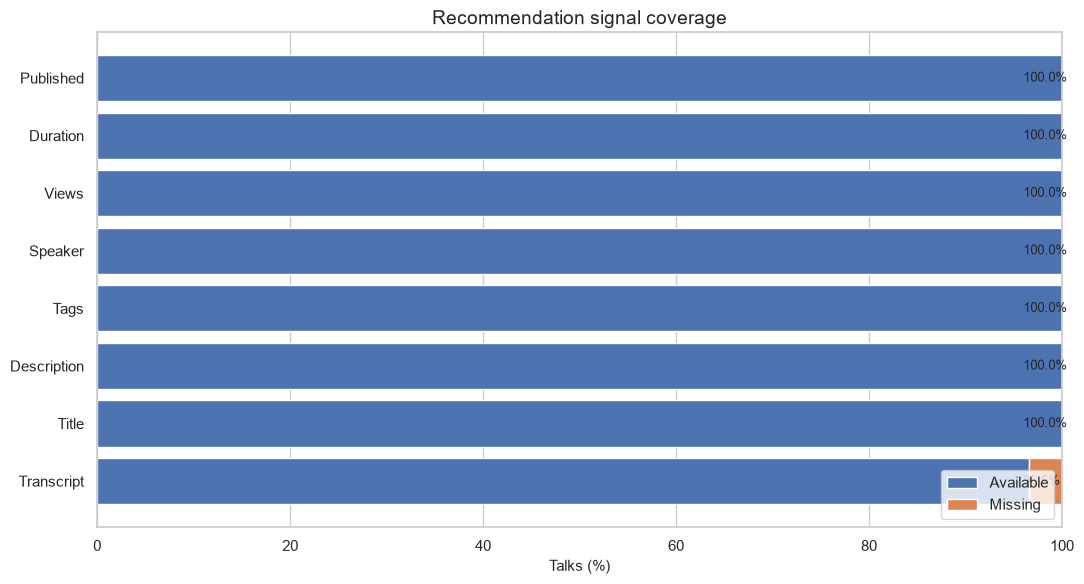

DESIGN IMPLICATION:
Transcript coverage is strong enough to make transcript-based content similarity the primary experiment.
Tags coverage: 100.0% | Description coverage: 100.0%


In [4]:
signal_fields = ["title", "transcript", "description", "tags", "speaker", "views", "duration", "published"]
signal_rows = []
for key in signal_fields:
    col = COL[key]
    if col is None:
        signal_rows.append({"Signal": key.title(), "Available %": 0, "Missing %": 100, "Column": "Not detected"})
    else:
        s = df[col]
        valid = s.notna()
        if s.dtype == "object" or pd.api.types.is_string_dtype(s):
            valid &= s.astype("string").str.strip().ne("")
        pct = valid.mean() * 100
        signal_rows.append({"Signal": key.title(), "Available %": pct, "Missing %": 100-pct, "Column": str(col)})
signal_df = pd.DataFrame(signal_rows).sort_values("Available %")
display(signal_df)

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(signal_df["Signal"], signal_df["Available %"], label="Available")
ax.barh(signal_df["Signal"], signal_df["Missing %"], left=signal_df["Available %"], label="Missing")
ax.set_xlim(0, 100)
ax.set_xlabel("Talks (%)")
ax.set_title("Recommendation signal coverage")
ax.legend(loc="lower right")
for i, row in enumerate(signal_df.itertuples()):
    ax.text(min(row[2]+1, 96), i, f"{row[2]:.1f}%", va="center", fontsize=9)
plt.tight_layout()
plt.savefig(VIZ_DIR / "01_recommendation_signal_coverage.png", dpi=160, bbox_inches="tight")
plt.show()

transcript_pct = float(signal_df.loc[signal_df.Signal.eq("Transcript"), "Available %"].iloc[0])
tag_pct = float(signal_df.loc[signal_df.Signal.eq("Tags"), "Available %"].iloc[0])
desc_pct = float(signal_df.loc[signal_df.Signal.eq("Description"), "Available %"].iloc[0])
print("DESIGN IMPLICATION:")
if transcript_pct >= 85:
    print("Transcript coverage is strong enough to make transcript-based content similarity the primary experiment.")
elif transcript_pct >= 50:
    print("Transcript coverage is partial. Use a fallback strategy combining transcript, description, title and tags.")
else:
    print("Transcript coverage is limited. Begin with metadata/title/description similarity and investigate transcript enrichment.")
print(f"Tags coverage: {tag_pct:.1f}% | Description coverage: {desc_pct:.1f}%")

## 5. Visual 2 — Topic coverage and catalogue concentration

**Question:** Does the catalogue provide enough breadth for users to discover different interests?

The chart shows the most frequent tags. The cumulative curve indicates how quickly the top topics account for the catalogue's tag assignments. This helps decide whether the interface should expose popular topic filters and whether diversity controls are needed.

,Topic,Talk/tag assignments
0,technology,727
1,science,567
2,global issues,501
3,culture,486
4,TEDx,450
5,design,418
6,business,348
7,entertainment,299
8,health,236
9,innovation,229


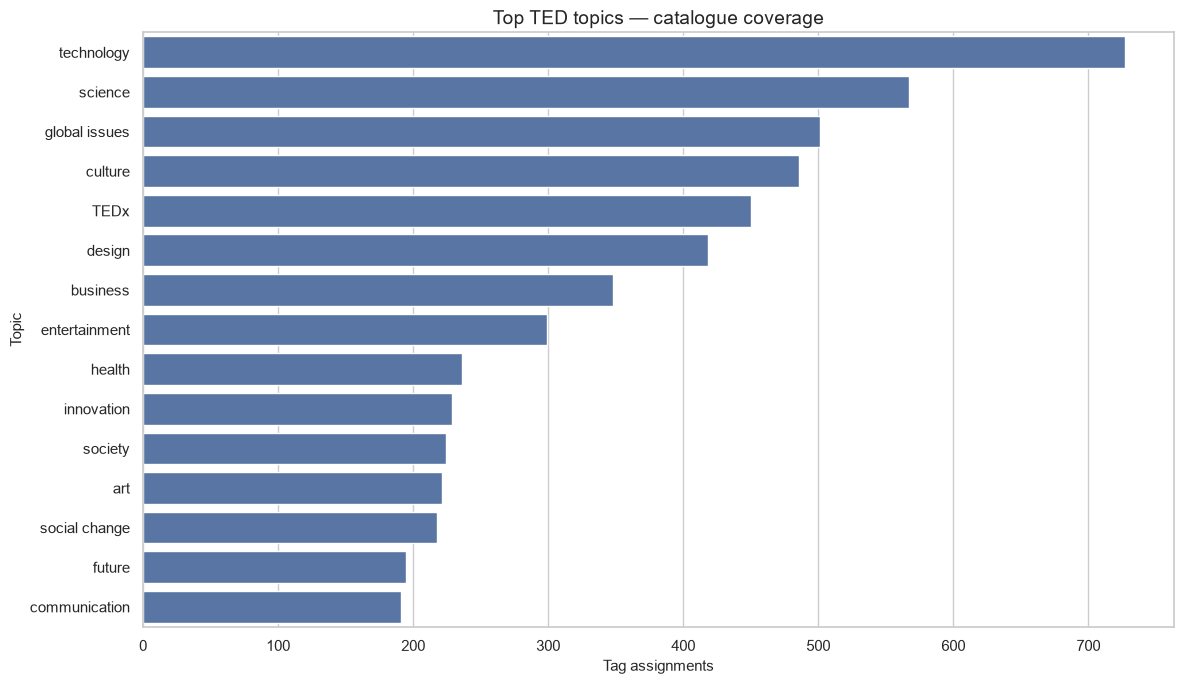

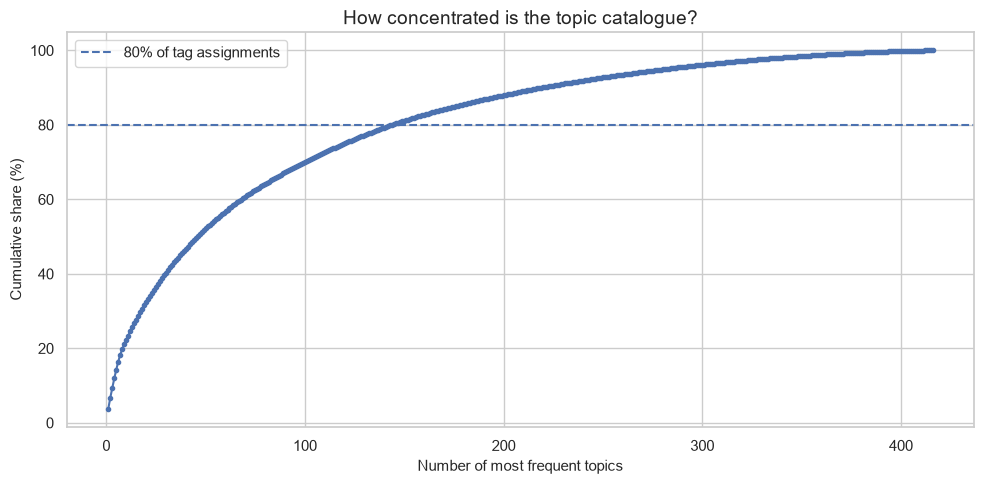

Unique tags detected: 416
DESIGN IMPLICATION: Use tags for onboarding and filtering, but avoid recommending only the globally most frequent topics.


In [5]:
def parse_tags(value):
    if pd.isna(value):
        return []
    if isinstance(value, (list, tuple, set)):
        vals = list(value)
    else:
        raw = str(value).strip()
        if not raw:
            return []
        try:
            parsed = ast.literal_eval(raw)
            vals = parsed if isinstance(parsed, (list, tuple, set)) else re.split(r"[,;|]", raw)
        except Exception:
            vals = re.split(r"[,;|]", raw)
    return [str(x).strip().strip("'\"") for x in vals if str(x).strip()]

if COL["tags"]:
    tag_lists = df[COL["tags"]].apply(parse_tags)
    exploded = tag_lists.explode().dropna()
    exploded = exploded[exploded.astype(str).str.len() > 0]
    tag_counts = exploded.value_counts()
    top_tags = tag_counts.head(15)
    display(top_tags.rename_axis("Topic").reset_index(name="Talk/tag assignments"))

    fig, ax1 = plt.subplots(figsize=(12, 7))
    sns.barplot(x=top_tags.values, y=top_tags.index, ax=ax1)
    ax1.set_title("Top TED topics — catalogue coverage")
    ax1.set_xlabel("Tag assignments")
    ax1.set_ylabel("Topic")
    plt.tight_layout()
    plt.savefig(VIZ_DIR / "02_top_topic_coverage.png", dpi=160, bbox_inches="tight")
    plt.show()

    topic_share = tag_counts / tag_counts.sum()
    cumulative = topic_share.cumsum()
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(np.arange(1, len(cumulative)+1), cumulative.values*100, marker=".")
    ax.axhline(80, linestyle="--", label="80% of tag assignments")
    ax.set_xlabel("Number of most frequent topics")
    ax.set_ylabel("Cumulative share (%)")
    ax.set_title("How concentrated is the topic catalogue?")
    ax.legend()
    plt.tight_layout()
    plt.savefig(VIZ_DIR / "03_topic_concentration.png", dpi=160, bbox_inches="tight")
    plt.show()
    print(f"Unique tags detected: {len(tag_counts):,}")
    print("DESIGN IMPLICATION: Use tags for onboarding and filtering, but avoid recommending only the globally most frequent topics.")
else:
    print("No tag/topic column detected; topic visualisations skipped.")

## 6. Visual 3 — Transcript availability by content fallback

**Question:** If a talk has no transcript, can the system still represent it using its description, title and tags?

This chart groups talks by which content components are available. It helps decide whether to exclude incomplete talks or keep them with a reduced-content fallback.

,Content group,Number of talks,Percentage
0,Transcript available,2464,96.627451
1,No transcript; description + title + tags,86,3.372549


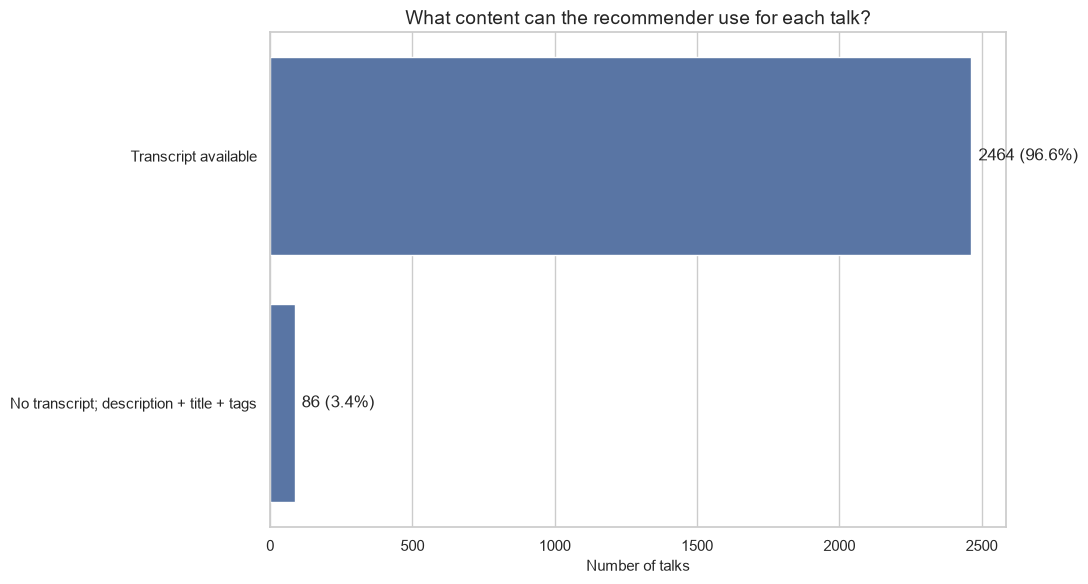

DESIGN IMPLICATION: Keep talks with missing transcripts when their title, description or tags still provide useful content.


In [6]:
content_keys = ["title", "description", "tags", "transcript"]
available = pd.DataFrame(index=df.index)
for key in content_keys:
    col = COL[key]
    if col is None:
        available[key] = False
    else:
        s = df[col]
        mask = s.notna()
        if s.dtype == "object" or pd.api.types.is_string_dtype(s):
            mask &= s.astype("string").str.strip().ne("")
        available[key] = mask

def content_group(row):
    if row["transcript"]:
        return "Transcript available"
    if row["description"] and row["title"] and row["tags"]:
        return "No transcript; description + title + tags"
    if row["title"] and row["tags"]:
        return "No transcript; title + tags"
    if row["title"] and row["description"]:
        return "No transcript; title + description"
    if row["title"]:
        return "Title only"
    return "Very limited content"

groups = available.apply(content_group, axis=1).value_counts()
group_df = groups.rename_axis("Content group").reset_index(name="Number of talks")
group_df["Percentage"] = group_df["Number of talks"] / len(df) * 100
display(group_df)

fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(data=group_df, x="Number of talks", y="Content group", ax=ax)
ax.set_title("What content can the recommender use for each talk?")
ax.set_xlabel("Number of talks")
ax.set_ylabel("")
for i, row in enumerate(group_df.itertuples()):
    ax.text(row[2] + max(group_df["Number of talks"])*0.01, i, f"{row[2]} ({row[3]:.1f}%)", va="center")
plt.tight_layout()
plt.savefig(VIZ_DIR / "04_content_fallback_groups.png", dpi=160, bbox_inches="tight")
plt.show()

print("DESIGN IMPLICATION: Keep talks with missing transcripts when their title, description or tags still provide useful content.")

## 7. Visual 4 — Transcript and description length

**Question:** Is the available text substantial enough to represent each talk?

Text length is a proxy for how much information is available, not a measure of quality. We compare transcript and description word counts to understand whether descriptions can be a useful fallback.

,count,mean,std,min,25%,50%,75%,90%,max
Transcript words,2464.0,2123.752029,995.511150,2.0,1395.75,2120.5,2804.25,3342.8,9418.0
Description words,2550.0,52.672549,18.453972,9.0,39.00,50.0,64.00,78.0,137.0


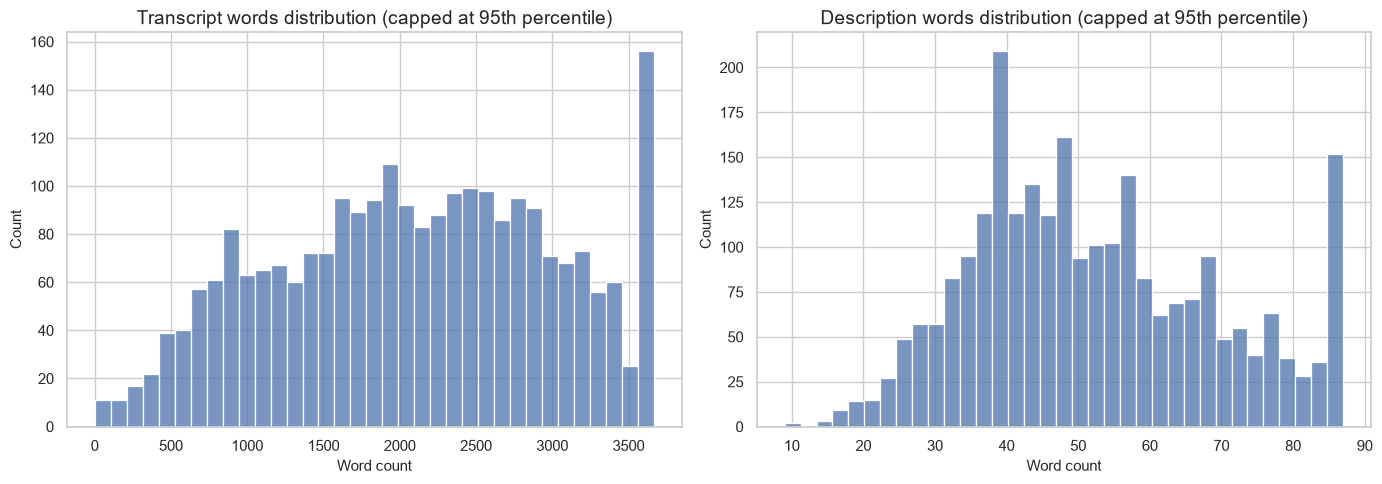

DESIGN IMPLICATION: Longer transcripts can carry richer semantic information; use descriptions/tags as fallback for sparse records.


In [7]:
def word_count_series(series):
    return series.fillna("").astype(str).str.findall(r"\b\w+\b").str.len()

length_data = pd.DataFrame(index=df.index)
if COL["transcript"]:
    length_data["Transcript words"] = word_count_series(df[COL["transcript"]])
if COL["description"]:
    length_data["Description words"] = word_count_series(df[COL["description"]])

if not length_data.empty:
    summary = length_data.replace(0, np.nan).describe(percentiles=[.25,.5,.75,.9]).T
    display(summary)
    plot_cols = [c for c in length_data if (length_data[c] > 0).any()]
    fig, axes = plt.subplots(1, len(plot_cols), figsize=(7*len(plot_cols), 5))
    if len(plot_cols) == 1:
        axes = [axes]
    for ax, col in zip(axes, plot_cols):
        vals = length_data.loc[length_data[col] > 0, col]
        sns.histplot(vals.clip(upper=vals.quantile(.95)), bins=35, ax=ax)
        ax.set_title(f"{col} distribution (capped at 95th percentile)")
        ax.set_xlabel("Word count")
    plt.tight_layout()
    plt.savefig(VIZ_DIR / "05_text_length_distributions.png", dpi=160, bbox_inches="tight")
    plt.show()
    print("DESIGN IMPLICATION: Longer transcripts can carry richer semantic information; use descriptions/tags as fallback for sparse records.")
else:
    print("No transcript or description field detected.")

## 8. Visual 5 — Popularity signal and its limitations

**Question:** Can popularity help rank recommendations?

Views can help identify widely watched talks, but popularity is not the same as personal relevance. A recommender should not simply return the most-viewed talks. This section inspects the distribution and its skew.

Views summary:


,Views
count,2.550000e+03
mean,1.698297e+06
std,2.498479e+06
min,5.044300e+04
25%,7.557928e+05
50%,1.124524e+06
75%,1.700760e+06
90%,3.051913e+06
95%,4.557041e+06
99%,1.202326e+07


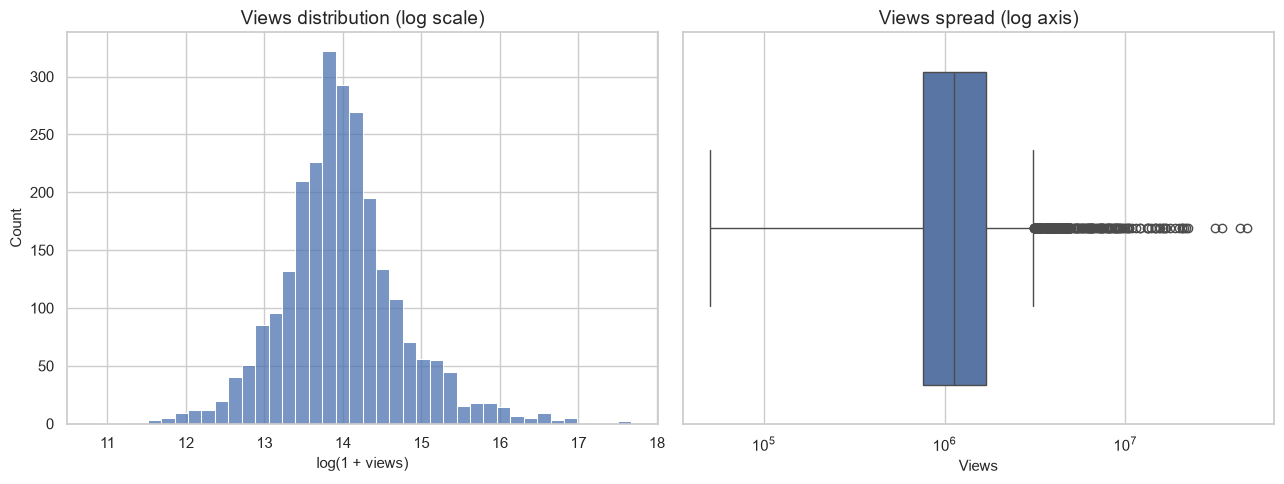

DESIGN IMPLICATION: Treat views as a secondary popularity feature, not as the main recommendation relevance score.


In [8]:
if COL["views"]:
    views = pd.to_numeric(df[COL["views"]], errors="coerce")
    valid_views = views.dropna()
    valid_views = valid_views[valid_views >= 0]
    if len(valid_views):
        print("Views summary:")
        display(valid_views.describe(percentiles=[.25,.5,.75,.9,.95,.99]).to_frame("Views"))
        fig, axes = plt.subplots(1, 2, figsize=(13, 5))
        sns.histplot(np.log1p(valid_views), bins=40, ax=axes[0])
        axes[0].set_title("Views distribution (log scale)")
        axes[0].set_xlabel("log(1 + views)")
        sns.boxplot(x=valid_views, ax=axes[1])
        axes[1].set_xscale("log")
        axes[1].set_title("Views spread (log axis)")
        axes[1].set_xlabel("Views")
        plt.tight_layout()
        plt.savefig(VIZ_DIR / "06_popularity_skew.png", dpi=160, bbox_inches="tight")
        plt.show()
        print("DESIGN IMPLICATION: Treat views as a secondary popularity feature, not as the main recommendation relevance score.")
    else:
        print("Views column exists but has no usable numeric values.")
else:
    print("No views/popularity field detected.")

## 9. Visual 6 — Duration and user choice

**Question:** Can the application support users who have limited time?

If duration is available, the system can offer filters such as “under 10 minutes” or “under 20 minutes”. This is a user-control feature, not a similarity feature.

Raw duration summary:


,Duration (raw units)
count,2550.000000
mean,826.510196
std,374.009138
min,135.000000
25%,577.000000
50%,848.000000
75%,1046.750000
max,5256.000000


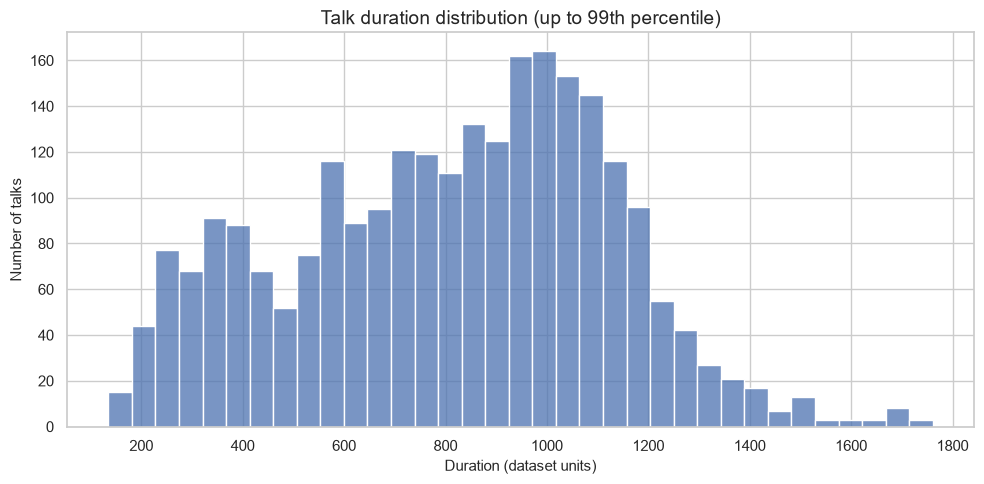

DESIGN IMPLICATION: If duration is stored in seconds, convert to minutes in the app and offer duration filters.


In [9]:
if COL["duration"]:
    duration = pd.to_numeric(df[COL["duration"]], errors="coerce")
    # TED main datasets commonly store duration in seconds. Inspect the range before interpreting.
    dur = duration.dropna()
    if len(dur):
        print("Raw duration summary:")
        display(dur.describe().to_frame("Duration (raw units)"))
        fig, ax = plt.subplots(figsize=(10, 5))
        sns.histplot(dur[dur <= dur.quantile(.99)], bins=35, ax=ax)
        ax.set_title("Talk duration distribution (up to 99th percentile)")
        ax.set_xlabel("Duration (dataset units)")
        ax.set_ylabel("Number of talks")
        plt.tight_layout()
        plt.savefig(VIZ_DIR / "07_duration_distribution.png", dpi=160, bbox_inches="tight")
        plt.show()
        print("DESIGN IMPLICATION: If duration is stored in seconds, convert to minutes in the app and offer duration filters.")
else:
    print("No duration field detected; duration-based filtering cannot be supported from this dataset alone.")

## 10. Visual 7 — Recommendation data readiness scorecard

**Question:** Which recommendation strategy is supported by the dataset today?

This is a capability scorecard, not a model-performance score. It distinguishes content information from genuine user-interaction evidence.

,Capability,Coverage %,Possible use
0,Transcript content,96.627451,Text similarity / semantic representation
1,Descriptions,100.000000,Fallback content representation
2,Topic tags,100.000000,Topic matching and user-selected interests
3,Talk identity,100.000000,Stable talk identity
4,Popularity,100.000000,Secondary ranking feature


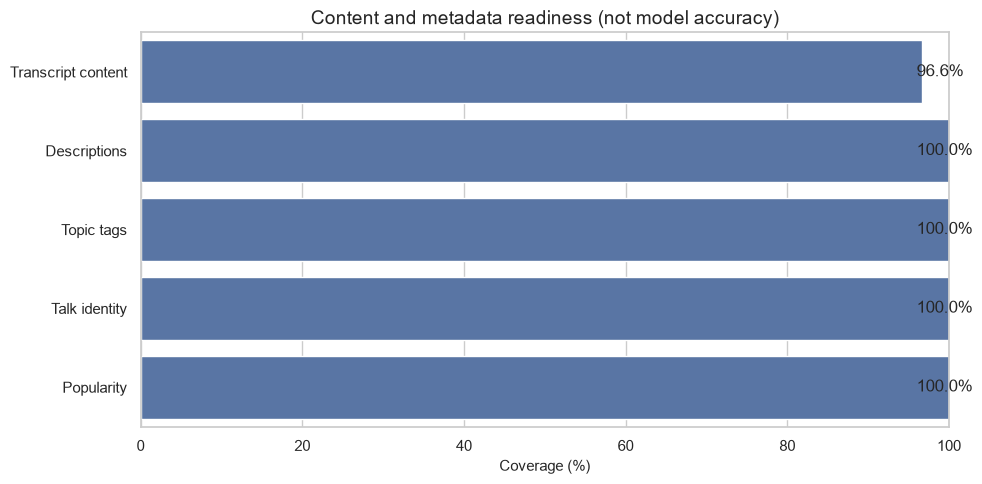

Potential user-interaction columns detected: None
No obvious user-level interaction fields were detected.

IMPORTANT: Aggregate ratings or views do not create a user-item interaction matrix.


In [10]:
def usable_pct(key):
    col = COL.get(key)
    if col is None:
        return 0.0
    s = df[col]
    valid = s.notna()
    if s.dtype == "object" or pd.api.types.is_string_dtype(s):
        valid &= s.astype("string").str.strip().ne("")
    return float(valid.mean()*100)

# Ratings are often aggregate counts per talk, not per-user events.
interaction_cols = [c for c in df.columns if any(t in str(c).lower() for t in
                    ["user_id", "user", "favorite", "favourite", "liked", "click", "watch_history", "interaction"])]
readiness = [
    ("Transcript content", usable_pct("transcript"), "Text similarity / semantic representation"),
    ("Descriptions", usable_pct("description"), "Fallback content representation"),
    ("Topic tags", usable_pct("tags"), "Topic matching and user-selected interests"),
    ("Talk identity", usable_pct("talk_id") if COL["talk_id"] else usable_pct("url"), "Stable talk identity"),
    ("Popularity", usable_pct("views"), "Secondary ranking feature"),
]
readiness_df = pd.DataFrame(readiness, columns=["Capability", "Coverage %", "Possible use"])
display(readiness_df)

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=readiness_df, x="Coverage %", y="Capability", ax=ax)
ax.set_xlim(0, 100)
ax.set_title("Content and metadata readiness (not model accuracy)")
ax.set_xlabel("Coverage (%)")
ax.set_ylabel("")
for i, row in enumerate(readiness_df.itertuples()):
    ax.text(min(row[2]+1, 96), i, f"{row[2]:.1f}%", va="center")
plt.tight_layout()
plt.savefig(VIZ_DIR / "08_recommender_readiness.png", dpi=160, bbox_inches="tight")
plt.show()

print("Potential user-interaction columns detected:", interaction_cols if interaction_cols else "None")
if interaction_cols:
    print("Inspect these fields manually: a column name alone does not prove that genuine user-item events exist.")
else:
    print("No obvious user-level interaction fields were detected.")
print("\nIMPORTANT: Aggregate ratings or views do not create a user-item interaction matrix.")

## 11. Evidence-based system design recommendation

The following recommendation is generated from the fields detected above. It is a project design decision, not a claim that a model has already been trained or evaluated.

In [11]:
design_lines = []
design_lines.append("# TED Talks Recommender — Evidence-based EDA Findings")
design_lines.append("")
design_lines.append(f"- Dataset size: **{len(df):,} talks** and **{df.shape[1]} columns**.")
design_lines.append(f"- Transcript coverage: **{usable_pct('transcript'):.1f}%**.")
design_lines.append(f"- Description coverage: **{usable_pct('description'):.1f}%**.")
design_lines.append(f"- Tag coverage: **{usable_pct('tags'):.1f}%**.")
design_lines.append(f"- Views coverage: **{usable_pct('views'):.1f}%**.")
design_lines.append("")
design_lines.append("## Recommended implementation direction")
if usable_pct("transcript") >= 85:
    design_lines.append("1. Start with transcript-based content similarity as the primary baseline.")
elif usable_pct("transcript") >= 50:
    design_lines.append("1. Use a hybrid content representation: transcript where available, with description/title/tags as fallback.")
else:
    design_lines.append("1. Start with title/description/tag-based content similarity; improve transcript availability before relying on transcript semantics.")
design_lines.append("2. Use tags as interpretable topic filters and as an additional matching signal.")
design_lines.append("3. Use popularity (views) only as a secondary ranking feature; relevance must remain central.")
design_lines.append("4. Add duration and speaker filters only when those fields are available and validated.")
if interaction_cols:
    design_lines.append("5. Inspect the detected interaction-related columns to verify whether they contain genuine user-level events.")
else:
    design_lines.append("5. Do not claim collaborative filtering from this dataset alone: no clear user-level interaction fields were detected.")
design_lines.append("")
design_lines.append("## Recommended pipeline")
design_lines.extend([
    "User selects topics / enters an interest",
    "        ↓",
    "Build a user-interest representation from selected topics or liked talks",
    "        ↓",
    "Generate candidate talks using TF-IDF or sentence embeddings",
    "        ↓",
    "Re-rank using topic match + semantic relevance + optional popularity/duration",
    "        ↓",
    "Show recommendations with explanations (matched topics / similar content)"
])
design_lines.append("")
design_lines.append("## Important limitation")
design_lines.append("This dataset-level EDA cannot prove recommendation quality. Module 3 should build text vectors; Module 4 should implement and evaluate recommendations with suitable relevance labels or user feedback.")
design_report = "\n".join(design_lines)
display(Markdown(design_report))
(REPORT_DIR / "problem_driven_eda_findings.md").write_text(design_report, encoding="utf-8")

# TED Talks Recommender — Evidence-based EDA Findings

- Dataset size: **2,550 talks** and **20 columns**.
- Transcript coverage: **96.6%**.
- Description coverage: **100.0%**.
- Tag coverage: **100.0%**.
- Views coverage: **100.0%**.

## Recommended implementation direction
1. Start with transcript-based content similarity as the primary baseline.
2. Use tags as interpretable topic filters and as an additional matching signal.
3. Use popularity (views) only as a secondary ranking feature; relevance must remain central.
4. Add duration and speaker filters only when those fields are available and validated.
5. Do not claim collaborative filtering from this dataset alone: no clear user-level interaction fields were detected.

## Recommended pipeline
User selects topics / enters an interest
        ↓
Build a user-interest representation from selected topics or liked talks
        ↓
Generate candidate talks using TF-IDF or sentence embeddings
        ↓
Re-rank using topic match + semantic relevance + optional popularity/duration
        ↓
Show recommendations with explanations (matched topics / similar content)

## Important limitation
This dataset-level EDA cannot prove recommendation quality. Module 3 should build text vectors; Module 4 should implement and evaluate recommendations with suitable relevance labels or user feedback.

1349

## 12. Export the analysis tables and finish

All charts are saved under `outputs/visualizations/problem_driven/`. The readiness table, signal coverage and findings report are saved separately so the evidence can be used in project documentation.

In [12]:
signal_df.to_csv(STATS_DIR / "recommendation_signal_coverage.csv", index=False)
readiness_df.to_csv(STATS_DIR / "recommender_readiness_scorecard.csv", index=False)
if COL["tags"] and "tag_counts" in globals():
    tag_counts.rename_axis("topic").reset_index(name="assignments").to_csv(STATS_DIR / "topic_coverage.csv", index=False)
if "group_df" in globals():
    group_df.to_csv(STATS_DIR / "content_fallback_groups.csv", index=False)

print("ANALYSIS COMPLETED")
print("Visualisations:", VIZ_DIR)
print("Reports:", REPORT_DIR)
print("Statistics:", STATS_DIR)
print("Charts created:", len(list(VIZ_DIR.glob("*.png"))))
print("Raw dataset modified: NO")

ANALYSIS COMPLETED
Visualisations: c:\Users\DELL\Desktop\INTERNSHIPS\Infosys_SpringBoard\Ted_Talk_Recommendation\Module_2_Data_Exploration_Preprocessing\outputs\visualizations\problem_driven
Reports: c:\Users\DELL\Desktop\INTERNSHIPS\Infosys_SpringBoard\Ted_Talk_Recommendation\Module_2_Data_Exploration_Preprocessing\outputs\reports
Statistics: c:\Users\DELL\Desktop\INTERNSHIPS\Infosys_SpringBoard\Ted_Talk_Recommendation\Module_2_Data_Exploration_Preprocessing\outputs\statistics
Charts created: 8
Raw dataset modified: NO


In [14]:
from pathlib import Path

print("PROJECT ROOT:", PROJECT_ROOT)
print("VISUALISATION FOLDER:", VIZ_DIR)
print("FOLDER EXISTS:", VIZ_DIR.exists())

png_files = list(VIZ_DIR.glob("*.png"))

print("\nSAVED VISUALISATIONS:")
if png_files:
    for file in png_files:
        print(file.name, "|", file.stat().st_size, "bytes")
else:
    print("No visualisation files found.")

print("\nTOTAL:", len(png_files))

PROJECT ROOT: c:\Users\DELL\Desktop\INTERNSHIPS\Infosys_SpringBoard\Ted_Talk_Recommendation
VISUALISATION FOLDER: c:\Users\DELL\Desktop\INTERNSHIPS\Infosys_SpringBoard\Ted_Talk_Recommendation\Module_2_Data_Exploration_Preprocessing\outputs\visualizations\problem_driven
FOLDER EXISTS: True

SAVED VISUALISATIONS:
01_recommendation_signal_coverage.png | 56103 bytes
02_top_topic_coverage.png | 58903 bytes
03_topic_concentration.png | 49613 bytes
04_content_fallback_groups.png | 38696 bytes
05_text_length_distributions.png | 69637 bytes
06_popularity_skew.png | 48924 bytes
07_duration_distribution.png | 43125 bytes
08_recommender_readiness.png | 47096 bytes

TOTAL: 8
